<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-09/galaxy-forests-networks.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

In [ ]:
#| code-fold: true
#| code-summary: Load supporting course files when running in Colab
from pathlib import Path
from urllib.request import urlretrieve
for name in ['lecture09_data.py', 'data/galaxy10_measurements.csv']:
    target = Path(name)
    if not target.exists():
        target.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve('https://raw.githubusercontent.com/MarcinPlodzien/deep-learning-for-scientific-discovery/main/notebooks/lecture-09/' + name, target)

# Three methods for galaxy classification

We compare a decision tree, random forest and dense neural network on the same smooth galaxies. First each image is represented by eight supplied measurements. We then repeat the comparison using reduced image pixels and display the predictions. The input representation is shared by all three methods within each comparison.

The images are Galaxy10 DECaLS, [Zenodo](https://doi.org/10.5281/zenodo.10845026). Keep `lecture09_data.py` and the supplied data alongside this notebook. The helper handles the image cache. The three-class task assumes that an object belongs to the smooth-galaxy subset.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_diabetes, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import balanced_accuracy_score, root_mean_squared_error, ConfusionMatrixDisplay
from threadpoolctl import threadpool_limits
threadpool_limits(limits=2)
SEED = 1975
Path("results").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)

from sklearn.metrics import accuracy_score

def save(fig, name):
    fig.savefig(f"figures/{name}.pdf", bbox_inches="tight")
    fig.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

fitting / validation / test galaxies: 3407 853 746
validation galaxy 4234 {'area': np.float64(0.327), 'brightness': np.float64(344.08), 'r50': np.float64(10.637), 'q': np.float64(0.909), 'red-blue': np.float64(0.246), 'C': np.float64(1.713), 'offset': np.float64(0.186), 'failure': np.float64(0.0)}
Fitting / validation / test 3407 853 746


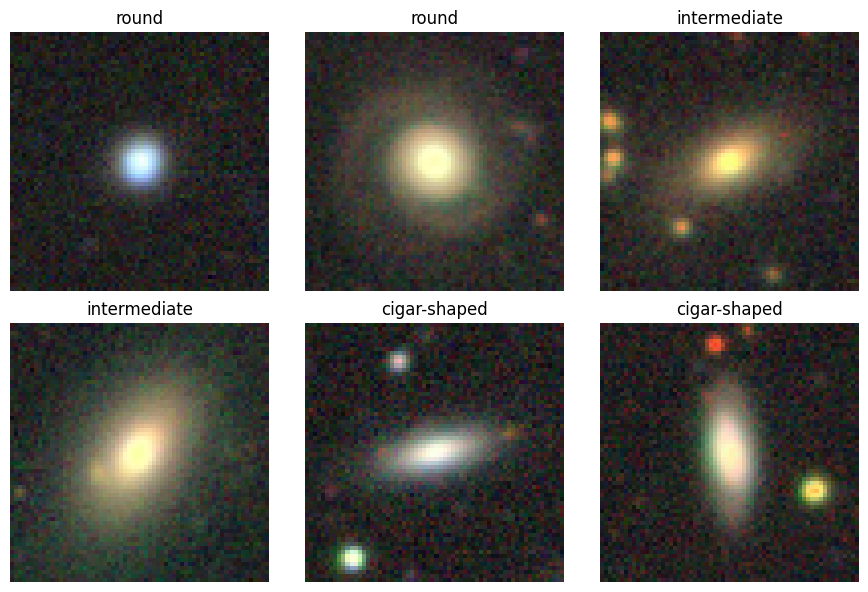

In [2]:
from lecture09_data import load_galaxies
from sklearn.impute import SimpleImputer
images, labels, descriptors, feature_names = load_galaxies()
table = pd.read_csv("data/galaxy10_measurements.csv")
smooth = table.catalogue_class.isin([2, 3, 4])
fit, val, test = [table[smooth & (table.split == role)].sort_values("split_order").index.to_numpy()
                  for role in ["fitting", "validation", "test"]]
y = labels - 2
class_names = ["round", "intermediate", "cigar-shaped"]
print("Fitting / validation / test", len(fit), len(val), len(test))
shown = np.concatenate([fit[y[fit] == k][:2] for k in range(3)])
fig, axes = plt.subplots(2, 3, figsize=(9, 6))
for ax, row in zip(axes.flat, shown):
    ax.imshow(images[row]); ax.set_title(class_names[y[row]]); ax.axis("off")
plt.tight_layout(); plt.show()

## Fit the three methods on measurements

The tree uses the depth selected in the preceding notebook. The forest and network settings below are fixed teaching configurations. `SimpleImputer` and `StandardScaler` learn only from fitting rows. Scikit-learn handles tree randomization and network optimization internally.

In [3]:
X = descriptors
models = {
    "Tree": make_pipeline(SimpleImputer(strategy="median"), DecisionTreeClassifier(
        max_depth=7, min_samples_leaf=10, random_state=SEED)),
    "Forest": make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(
        n_estimators=300, max_features=1., min_samples_leaf=1, random_state=SEED, n_jobs=2)),
    "Network": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), MLPClassifier(
        hidden_layer_sizes=(64, 32), alpha=.1, batch_size=128, max_iter=1000,
        n_iter_no_change=30, random_state=SEED))}
for model in models.values():
    model.fit(X[fit], y[fit])
display(pd.DataFrame({"model": list(models), "validation BA": [balanced_accuracy_score(
    y[val], m.predict(X[val])) for m in models.values()]}))

,model,validation BA
0,Tree,0.873920
1,Forest,0.891578
2,Network,0.880070


## Evaluate the fixed models

The same test galaxies are evaluated by every method. Compare the confusion matrices as well as the average scores. The course split has been used before, so these scores are illustrative.

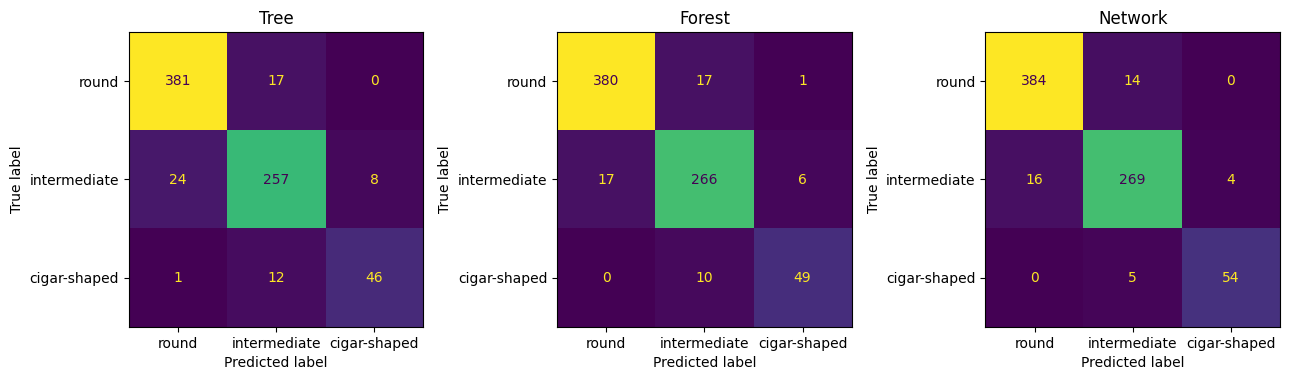

,model,accuracy,balanced_accuracy
0,Tree,0.916890,0.875407
1,Forest,0.931635,0.901899
2,Network,0.947721,0.936958


In [4]:
descriptor_rows = []
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, model) in zip(axes, models.items()):
    pred = model.predict(X[test])
    descriptor_rows.append(dict(model=name, accuracy=accuracy_score(y[test], pred),
                                balanced_accuracy=balanced_accuracy_score(y[test], pred)))
    ConfusionMatrixDisplay.from_predictions(y[test], pred, display_labels=class_names, ax=ax, colorbar=False)
    ax.set_title(name)
fig.tight_layout(); save(fig, "simple_galaxy_descriptor_confusion")
display(pd.DataFrame(descriptor_rows))
with open("results/simple_galaxy_descriptors.json", "w") as stream:
    json.dump(descriptor_rows, stream, indent=2)

## Classifying the galaxy images directly

The earlier models received eight measured descriptors. We now give all three families the same reduced images. Average each 4 by 4 block of the 64 by 64 RGB image to obtain 16 by 16 by 3 values, divide by 255 and flatten to 768 inputs. The input contains image brightness patterns rather than the named roundness and concentration measurements. Reduction keeps the CPU example small and can discard fine structure.

The task still assumes a smooth galaxy and predicts round, intermediate or cigar-shaped. We reuse the same fitting, validation and test objects. Compare validation accuracies for trees of depths 3 and 7. The forest and dense-network settings below are fixed in advance to keep the application short. The network uses an internal early-stopping subset of its fitting data. Freeze these choices before computing test scores. This experiment has a different representation from the descriptor comparison and is not a search for the best image classifier.

In [5]:
pixel_X = images.astype(np.float32).reshape(-1, 16, 4, 16, 4, 3).mean(axis=(2, 4)).reshape(-1, 768) / 255.
pixel_trees = [DecisionTreeClassifier(max_depth=depth, min_samples_leaf=10, random_state=SEED)
               .fit(pixel_X[fit], y[fit]) for depth in [3, 7]]
pixel_validation = [balanced_accuracy_score(y[val], m.predict(pixel_X[val])) for m in pixel_trees]
pixel_models = {
    "Tree": pixel_trees[int(np.argmax(pixel_validation))],
    "Forest": RandomForestClassifier(n_estimators=100, max_features="sqrt", min_samples_leaf=2,
                                     random_state=SEED, n_jobs=2).fit(pixel_X[fit], y[fit]),
    "Network": MLPClassifier(hidden_layer_sizes=(64,), alpha=1., batch_size=128,
                             max_iter=200, early_stopping=True, validation_fraction=.1,
                             n_iter_no_change=15, random_state=SEED).fit(pixel_X[fit], y[fit])}
display(pd.DataFrame({"tree_depth": [3, 7], "validation_BA": pixel_validation}))
display(pd.DataFrame({"model": list(pixel_models), "validation_BA": [balanced_accuracy_score(
    y[val], m.predict(pixel_X[val])) for m in pixel_models.values()]}))

,tree_depth,validation_BA
0,3,0.518144
1,7,0.625194


,model,validation_BA
0,Tree,0.625194
1,Forest,0.665171
2,Network,0.659779


## Image evaluation and displayed predictions

The settings are frozen. Evaluate each model on the same test objects and compare class recalls as well as the average score. The displayed objects are the first two test rows of each class, chosen independently of their predictions. A model can make the same mistake under both representations, and a compact representation may preserve useful information while discarding other structure.

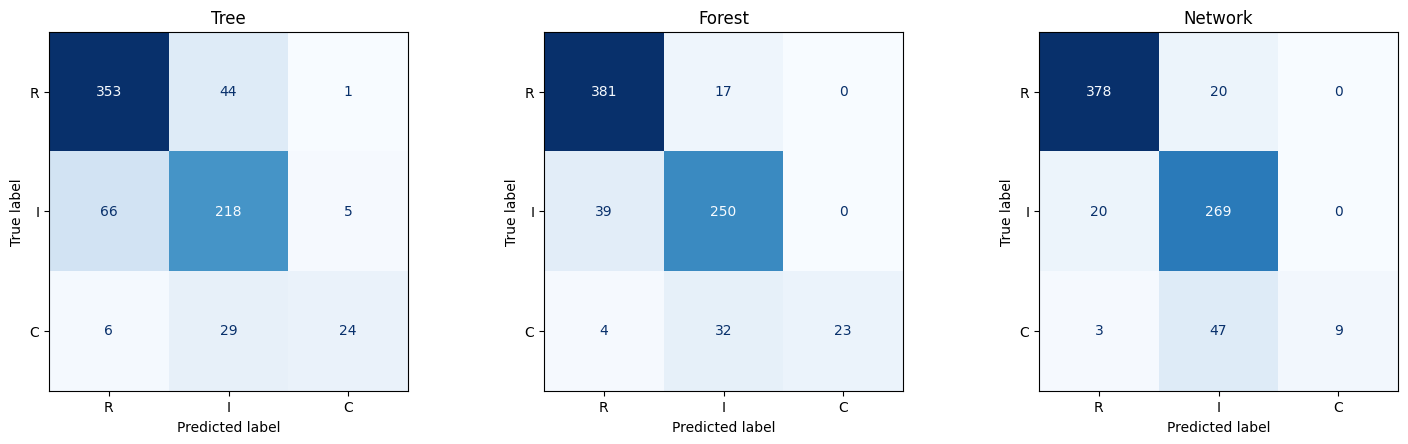

,model,accuracy,balanced_accuracy
0,Tree,0.797587,0.682680
1,Forest,0.876676,0.737390
2,Network,0.879357,0.677696


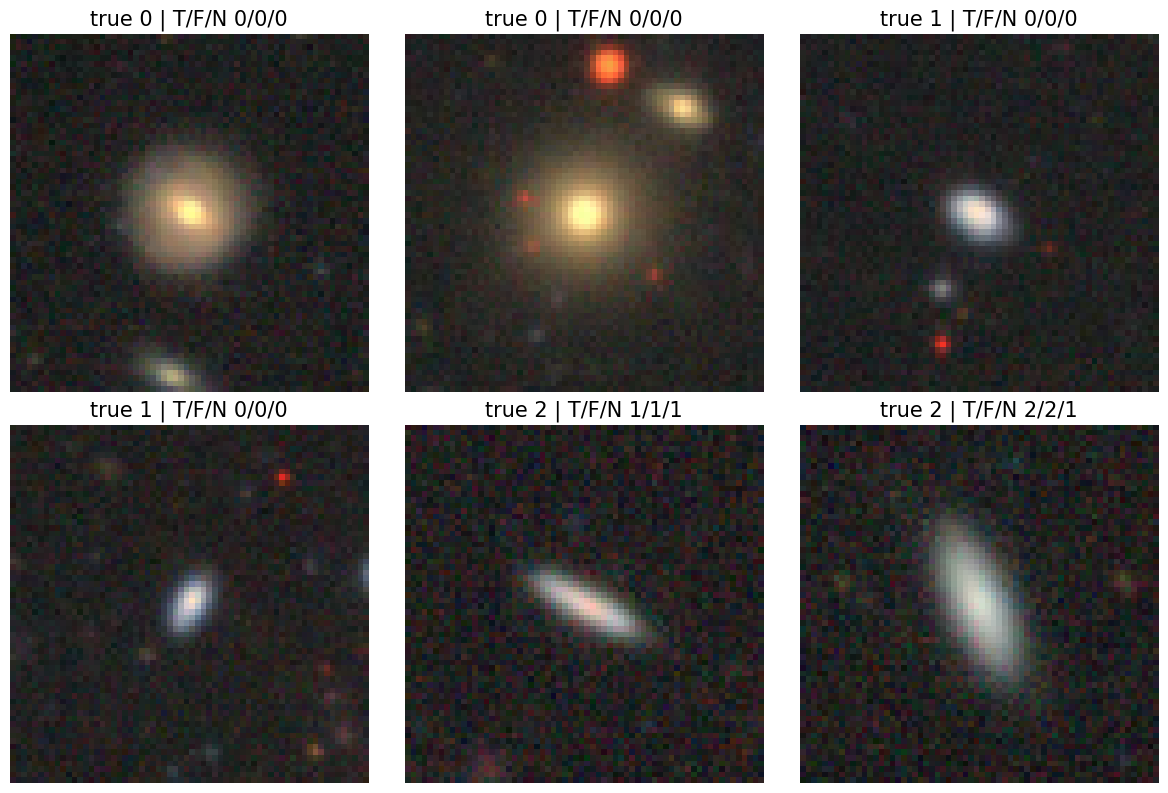

In [6]:
pixel_test_rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, model) in zip(axes, pixel_models.items()):
    prediction = model.predict(pixel_X[test])
    pixel_test_rows.append(dict(model=name, accuracy=accuracy_score(y[test], prediction),
                                balanced_accuracy=balanced_accuracy_score(y[test], prediction)))
    ConfusionMatrixDisplay.from_predictions(y[test], prediction, display_labels=["R", "I", "C"],
                                           ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
fig.tight_layout()
save(fig, "galaxy_pixel_comparison_confusion")
pixel_results = pd.DataFrame(pixel_test_rows)
display(pixel_results)
shown = np.concatenate([test[y[test] == k][:2] for k in range(3)])
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, row in zip(axes.flat, shown):
    ax.imshow(images[row])
    answers = [int(m.predict(pixel_X[row:row+1])[0]) for m in pixel_models.values()]
    ax.set_title(f"true {y[row]} | T/F/N {answers[0]}/{answers[1]}/{answers[2]}", fontsize=15)
    ax.axis("off")
fig.tight_layout()
save(fig, "galaxy_pixel_comparison_predictions")
pixel_results.to_csv("results/galaxy_pixel_comparison.csv", index=False)
with open("results/galaxy_pixel_comparison.json", "w") as stream:
    json.dump(dict(representation="16x16 RGB block averages, scaled to [0,1]", class_order=class_names,
                   fitting_size=len(fit), validation_size=len(val), test_size=len(test),
                   tree_validation_BA=pixel_validation, test=pixel_test_rows), stream, indent=2)

## Comparing representations

Compare these scores with the descriptor table earlier in the notebook. Describe which information each representation supplies and which details the 16-pixel reduction can remove. Identify a displayed disagreement and inspect its input. The scores concern these fixed configurations and this smooth-galaxy subset. A convolutional network learning spatial features or a different image reduction would be another experiment.